In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
adata=sc.read_h5ad('/home/julia/final_clustering.h5ad')

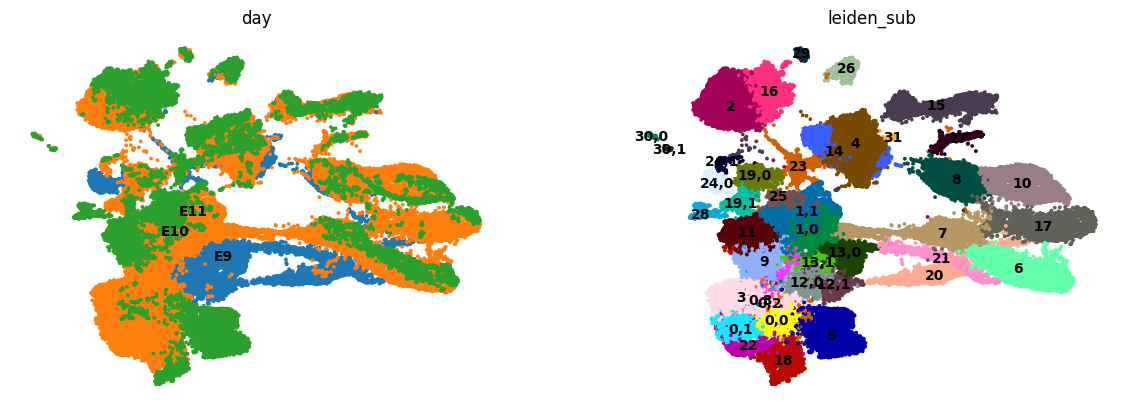

In [3]:
sc.pl.umap(adata, color=["day",  'leiden_sub'], frameon=False, legend_loc='on data', size=30)

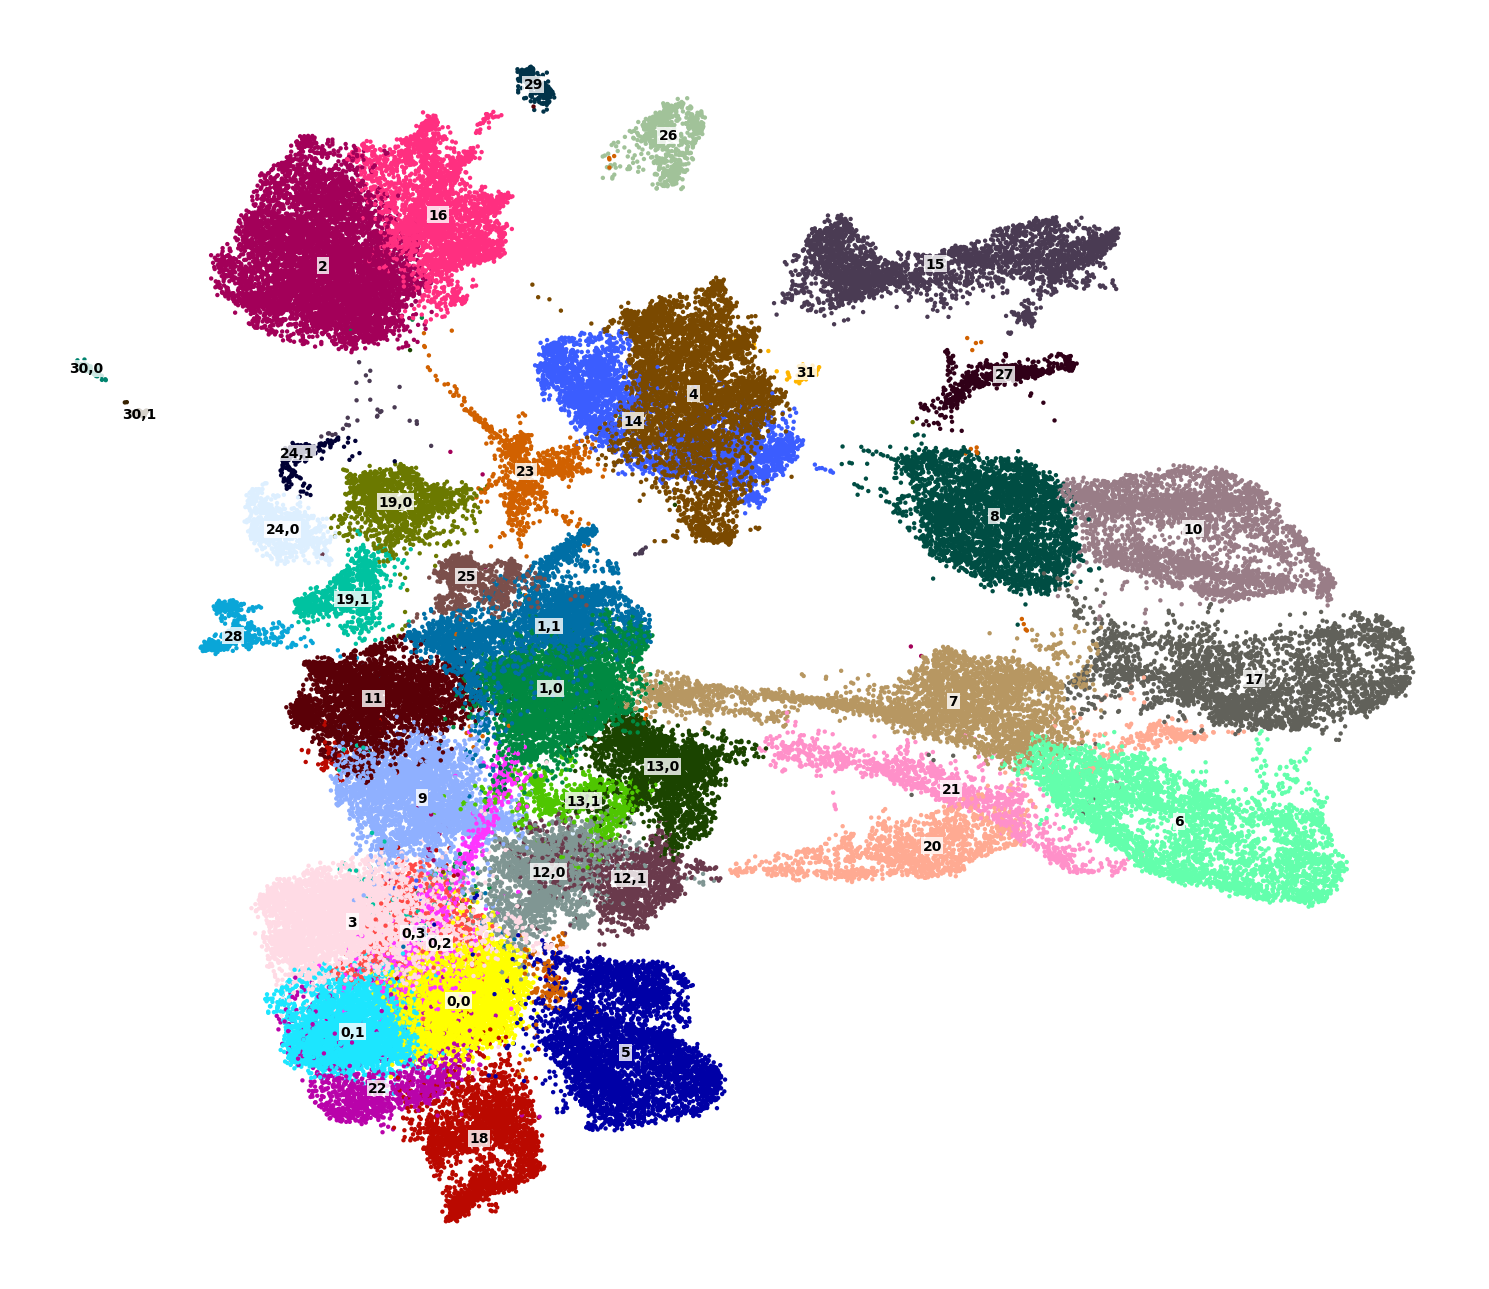

In [4]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(15, 13))

# Plot without automatic labels
sc.pl.umap(
    adata,
    color="leiden_sub",
    frameon=False,
    size=40,
    legend_loc=None,
    ax=ax,
    show=False,
    title=""
)

# Add labels manually for every cluster
coords = adata.obsm["X_umap"]
clusters = adata.obs["leiden_sub"].astype(str).to_numpy()

for cl in adata.obs["leiden_sub"].cat.categories:
    mask = clusters == str(cl)
    if not mask.any():
        continue

    x, y = np.median(coords[mask], axis=0)

    ax.text(
        x, y, str(cl),
        fontsize=10,
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none",
            pad=1
        ),
        zorder=100
    )

plt.tight_layout()
plt.show()

cell_type
Unknown                  40939
Mesenchyme               10446
Epibranchial ganglia      9305
Otic                      8148
Otic ganglion             7168
Epibranchial              6802
Trigeminal ganglion       4863
CNS                       3201
Trigeminal                1329
Lens development           959
Neural crest & SCPs        664
Olfactory & pituitary      642
Endothelial                237
Macrophages                119
Erythroid                   68
Name: count, dtype: int64


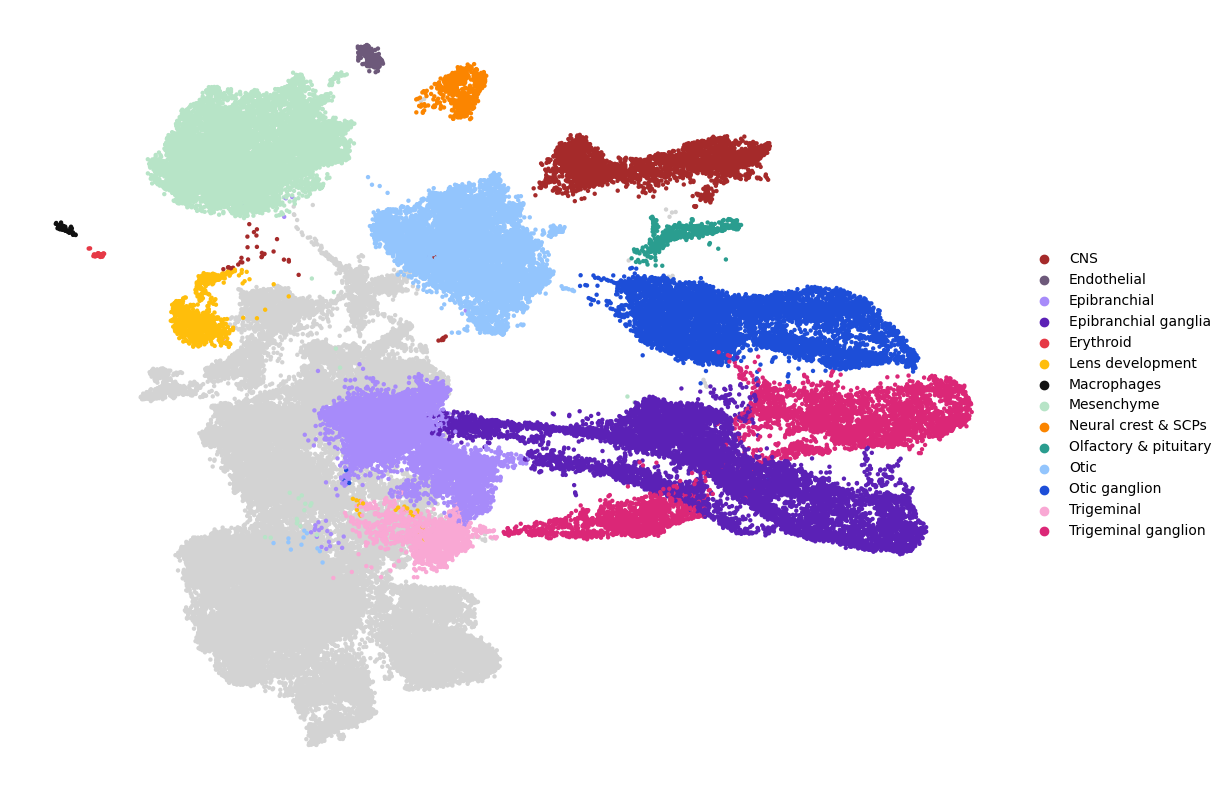

In [5]:
cluster_annotation = {
    "0,0": "Unknown", "0,1": "Unknown", "0,2": "Unknown",
    "1,0": "Epibranchial", "1,1": "Unknown",
    "2": "Mesenchyme", "3": "Unknown", "4": "Otic", "5": "Unknown",
    "6": "Epibranchial ganglia", "7": "Epibranchial ganglia",
    "8": "Otic ganglion", "9": "Unknown", "10": "Otic ganglion", "11": "Unknown",
    "12,0": "Unknown", "12,1": "Trigeminal",
    "13,0": "Epibranchial", "14": "Otic", "15": "CNS", "16": "Mesenchyme",
    "17": "Trigeminal ganglion", "18": "Unknown", "19,0": "Unknown", "19,1": "Unknown",
    "20": "Trigeminal ganglion", "21": "Epibranchial ganglia", "22": "Unknown", "23": "Unknown",
    "24,0": "Lens development", "24,1": "Lens development", "25": "Unknown",
    "26": "Neural crest & SCPs", "27": "Olfactory & pituitary", "28": "Unknown",
    "29": "Endothelial", "30,0": "Macrophages", "30,1": "Erythroid", "31": "Otic",
}

adata.obs["cell_type"] = (
    adata.obs["leiden_sub"].astype(str)
    .map(cluster_annotation)
    .fillna("Unknown")
    .astype("category")
)
print(adata.obs["cell_type"].value_counts())

type_colors = {
    "Otic":                  "#93C5FD",   # light blue
    "Otic ganglion":         "#1D4ED8",   # deep blue
    "Epibranchial":          "#A78BFA",   # light purple
    "Epibranchial ganglia":  "#5B21B6",   # deep purple
    "Trigeminal":            "#F9A8D4",   # light pink
    "Trigeminal ganglion":   "#DB2777",   # magenta
    "Olfactory & pituitary": "#2A9D8F",   # teal
    "Lens development":      "#FFBE0B",   # gold
    "Mesenchyme":            "#B7E4C7",   # soft green
    "Neural crest & SCPs":   "#FB8500",   # orange
    "Endothelial":           "#6D597A",   # muted plum
    "Macrophages":           "#111111",   # black
    "Erythroid":             "#E63946",   # red
     "CNS":             "brown",   # red
    "Unknown":               "#D3D3D3",   # grey
}

cats = adata.obs["cell_type"].cat.categories
adata.uns["cell_type_colors"] = [type_colors.get(c, "#D3D3D3") for c in cats]
missing = [c for c in cats if c not in type_colors]
if missing:
    print("no color assigned (shown grey):", missing)

# plot: Unknown as grey background, colored types on top
known = [c for c in cats if c != "Unknown"]
fig, ax = plt.subplots(figsize=(13, 10))
sc.pl.umap(adata, color="cell_type", groups=known, na_color="#D3D3D3",
           na_in_legend=False, frameon=False, size=40, ax=ax, show=False, title="")
for coll in ax.collections:
    coll.set_rasterized(True)
plt.show()

fig.savefig("/home/julia/UMAP_cell_type_final.pdf", dpi=300, bbox_inches="tight")

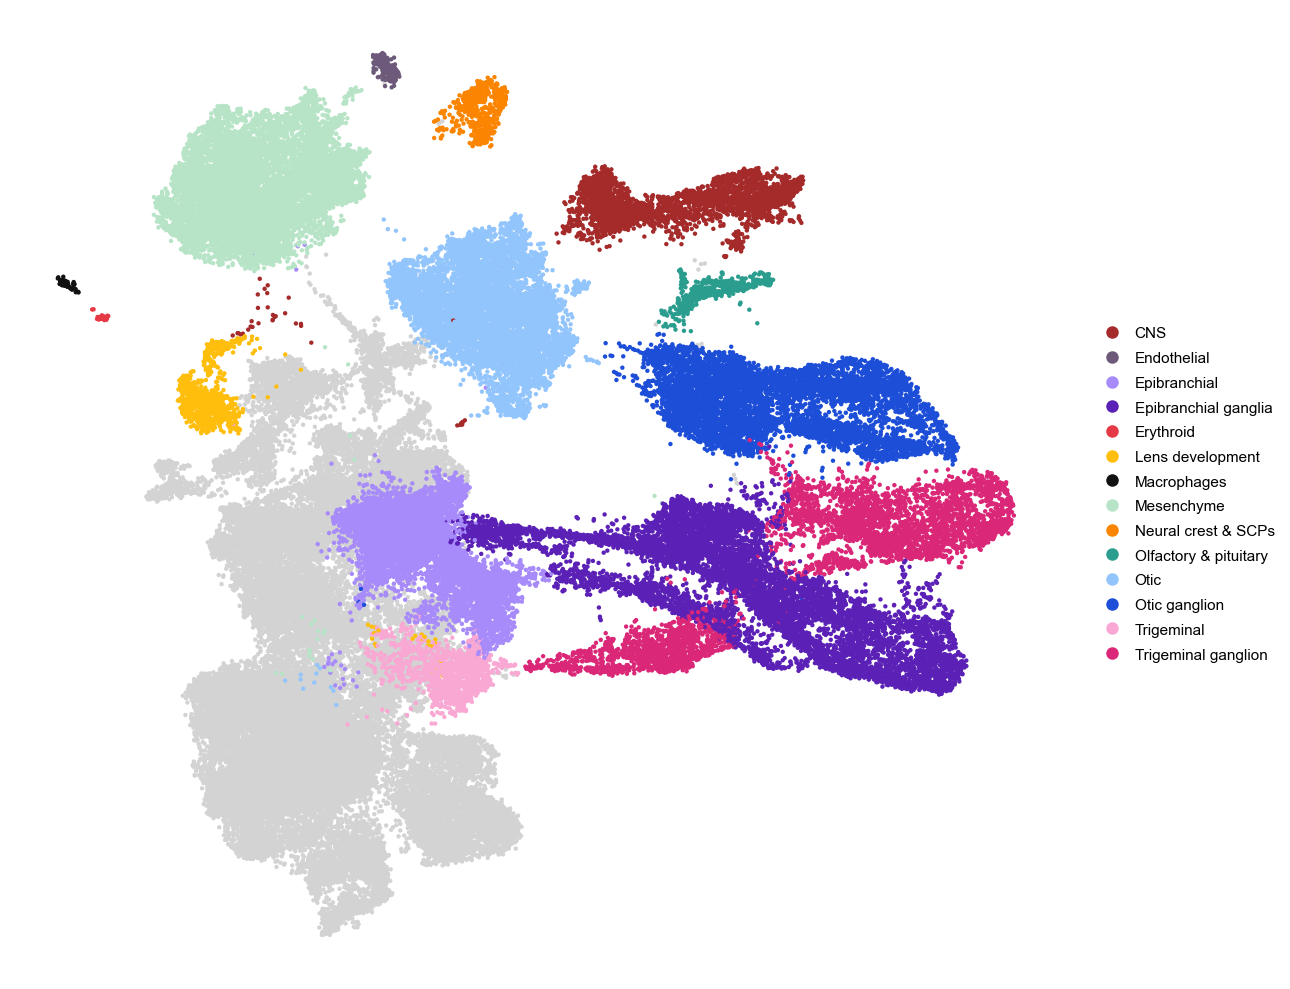

Saved: /home/julia/data/placodes/SCENIC_sub_1_5/UMAP_cell_type_final.pdf


In [6]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import scanpy as sc
from matplotlib.lines import Line2D

# ============================================================
# 1. FIGURE SETTINGS
# ============================================================

FIGSIZE = (13, 10)
POINT_SIZE = 40

LEGEND_FONT_SIZE = 11
LEGEND_MARKER_SIZE = 9
LEGEND_COLUMNS = 1

DPI = 300
PDF_PATH = "/home/julia/data/placodes/SCENIC_sub_1_5/UMAP_cell_type_final.pdf"

mpl.rcParams.update({
    "font.family": "Arial",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "pdf.compression": 9,
})

# ============================================================
# 2. ASSIGN COLORS
# ============================================================

cats = adata.obs["cell_type"].cat.categories

adata.uns["cell_type_colors"] = [
    type_colors.get(c, "#D3D3D3")
    for c in cats
]

known = [c for c in cats if c != "Unknown"]

# ============================================================
# 3. PLOT UMAP
# ============================================================

fig, ax = plt.subplots(figsize=FIGSIZE)

sc.pl.umap(
    adata,
    color="cell_type",
    groups=known,
    palette=type_colors,
    na_color="#D3D3D3",
    na_in_legend=False,
    frameon=False,
    size=POINT_SIZE,
    ax=ax,
    show=False,
    title="",
    legend_loc=None,
)

# ============================================================
# 4. RASTERIZE UMAP POINTS ONLY
# ============================================================

for collection in ax.collections:
    collection.set_rasterized(True)

# ============================================================
# 5. CREATE CUSTOM COLORED LEGEND
# ============================================================

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=type_colors[c],
        markeredgecolor="none",
        markersize=LEGEND_MARKER_SIZE,
        label=c
    )
    for c in known
]

ax.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=LEGEND_FONT_SIZE,
    ncol=LEGEND_COLUMNS,
    handletextpad=0.5,
    labelspacing=0.7,
)

# ============================================================
# 6. CLEAN FIGURE
# ============================================================

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()

# ============================================================
# 7. SAVE PDF
# ============================================================

fig.savefig(
    PDF_PATH,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Saved: {PDF_PATH}")

In [7]:
adata.write_h5ad('main_annotat_3_11.h5ad')

In [8]:
import numpy as np
import pandas as pd
import scanpy as sc

KEY = "cell_type"

adata.obs[KEY] = (
    adata.obs[KEY].astype(str).astype("category")
)

cats = list(adata.obs[KEY].cat.categories)

# Differential expression: each cell type vs all others
sc.tl.rank_genes_groups(
    adata,
    groupby=KEY,
    method="wilcoxon",
    use_raw=False,
    pts=True,
    reference="rest",
    key_added="celltype_markers"
)

# Extract markers
tables = []

for ct in cats:
    df = sc.get.rank_genes_groups_df(
        adata,
        group=ct,
        key="celltype_markers"
    ).copy()

    df["cell_type"] = ct
    tables.append(df)

mk = pd.concat(tables, ignore_index=True)

# Exclude technical and less informative genes
bad = mk["names"].str.contains(
    r"^(mt-|Rpl|Rps|Gm\d+|Hb[ab]|Hist)",
    case=False,
    regex=True
)

mk = mk[~bad].copy()

# Specificity calculations
mk["pct_diff"] = (
    mk["pct_nz_group"] -
    mk["pct_nz_reference"]
)

mk["pct_ratio"] = (
    (mk["pct_nz_group"] + 0.01) /
    (mk["pct_nz_reference"] + 0.01)
)

mk["specificity_score"] = (
    mk["pct_diff"].clip(lower=0)
    * np.log2(mk["pct_ratio"].clip(lower=1))
    * np.log2(mk["logfoldchanges"].clip(lower=0) + 1)
)

# Filter highly specific markers
mk_specific = mk[
    (mk["pvals_adj"] < 0.01) &
    (mk["logfoldchanges"] > 1.5) &
    (mk["pct_nz_group"] > 0.30) &
    (mk["pct_diff"] > 0.20)
].copy()

mk_specific = mk_specific.sort_values(
    "specificity_score",
    ascending=False
)

print("Specific markers:", len(mk_specific))

/tmp/ipykernel_2423586/1131240038.py:40: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  bad = mk["names"].str.contains(


Specific markers: 2815



FINAL MARKER GENES

Otic: 3 — Lmx1a, Pax2, Oc90
Otic ganglion: 3 — Fgf10, Kctd8, Ncam2
Epibranchial: 3 — Fgf8, Pax9, Pax1
Epibranchial ganglia: 3 — Phox2b, Phox2a, Neurog2
Trigeminal: 3 — Foxi2, Phlda2, Wnt6
Trigeminal ganglion: 3 — Pou4f1, Prrxl1, Prdm12
Lens development: 3 — Aldh1a3, Hmx1, Pax6
Olfactory & pituitary: 3 — Neurog1, Lhx2, Fezf1
Neural crest & SCPs: 3 — Foxd3, Plp1, Sox10
CNS: 3 — Sox1, Foxb1, Sox3
Macrophages: 3 — Mrc1, C1qc, Csf1r
Mesenchyme: 3 — Twist1, Twist2, Prrx1
Endothelial: 3 — Cdh5, Pecam1, Kdr
Erythroid: 3 — Hba-a2, Hbb-bh1, Hba-x
Saved PDF: /home/julia/Dotplot_cell_type_final.pdf
Saved SVG: /home/julia/Dotplot_cell_type_final.svg


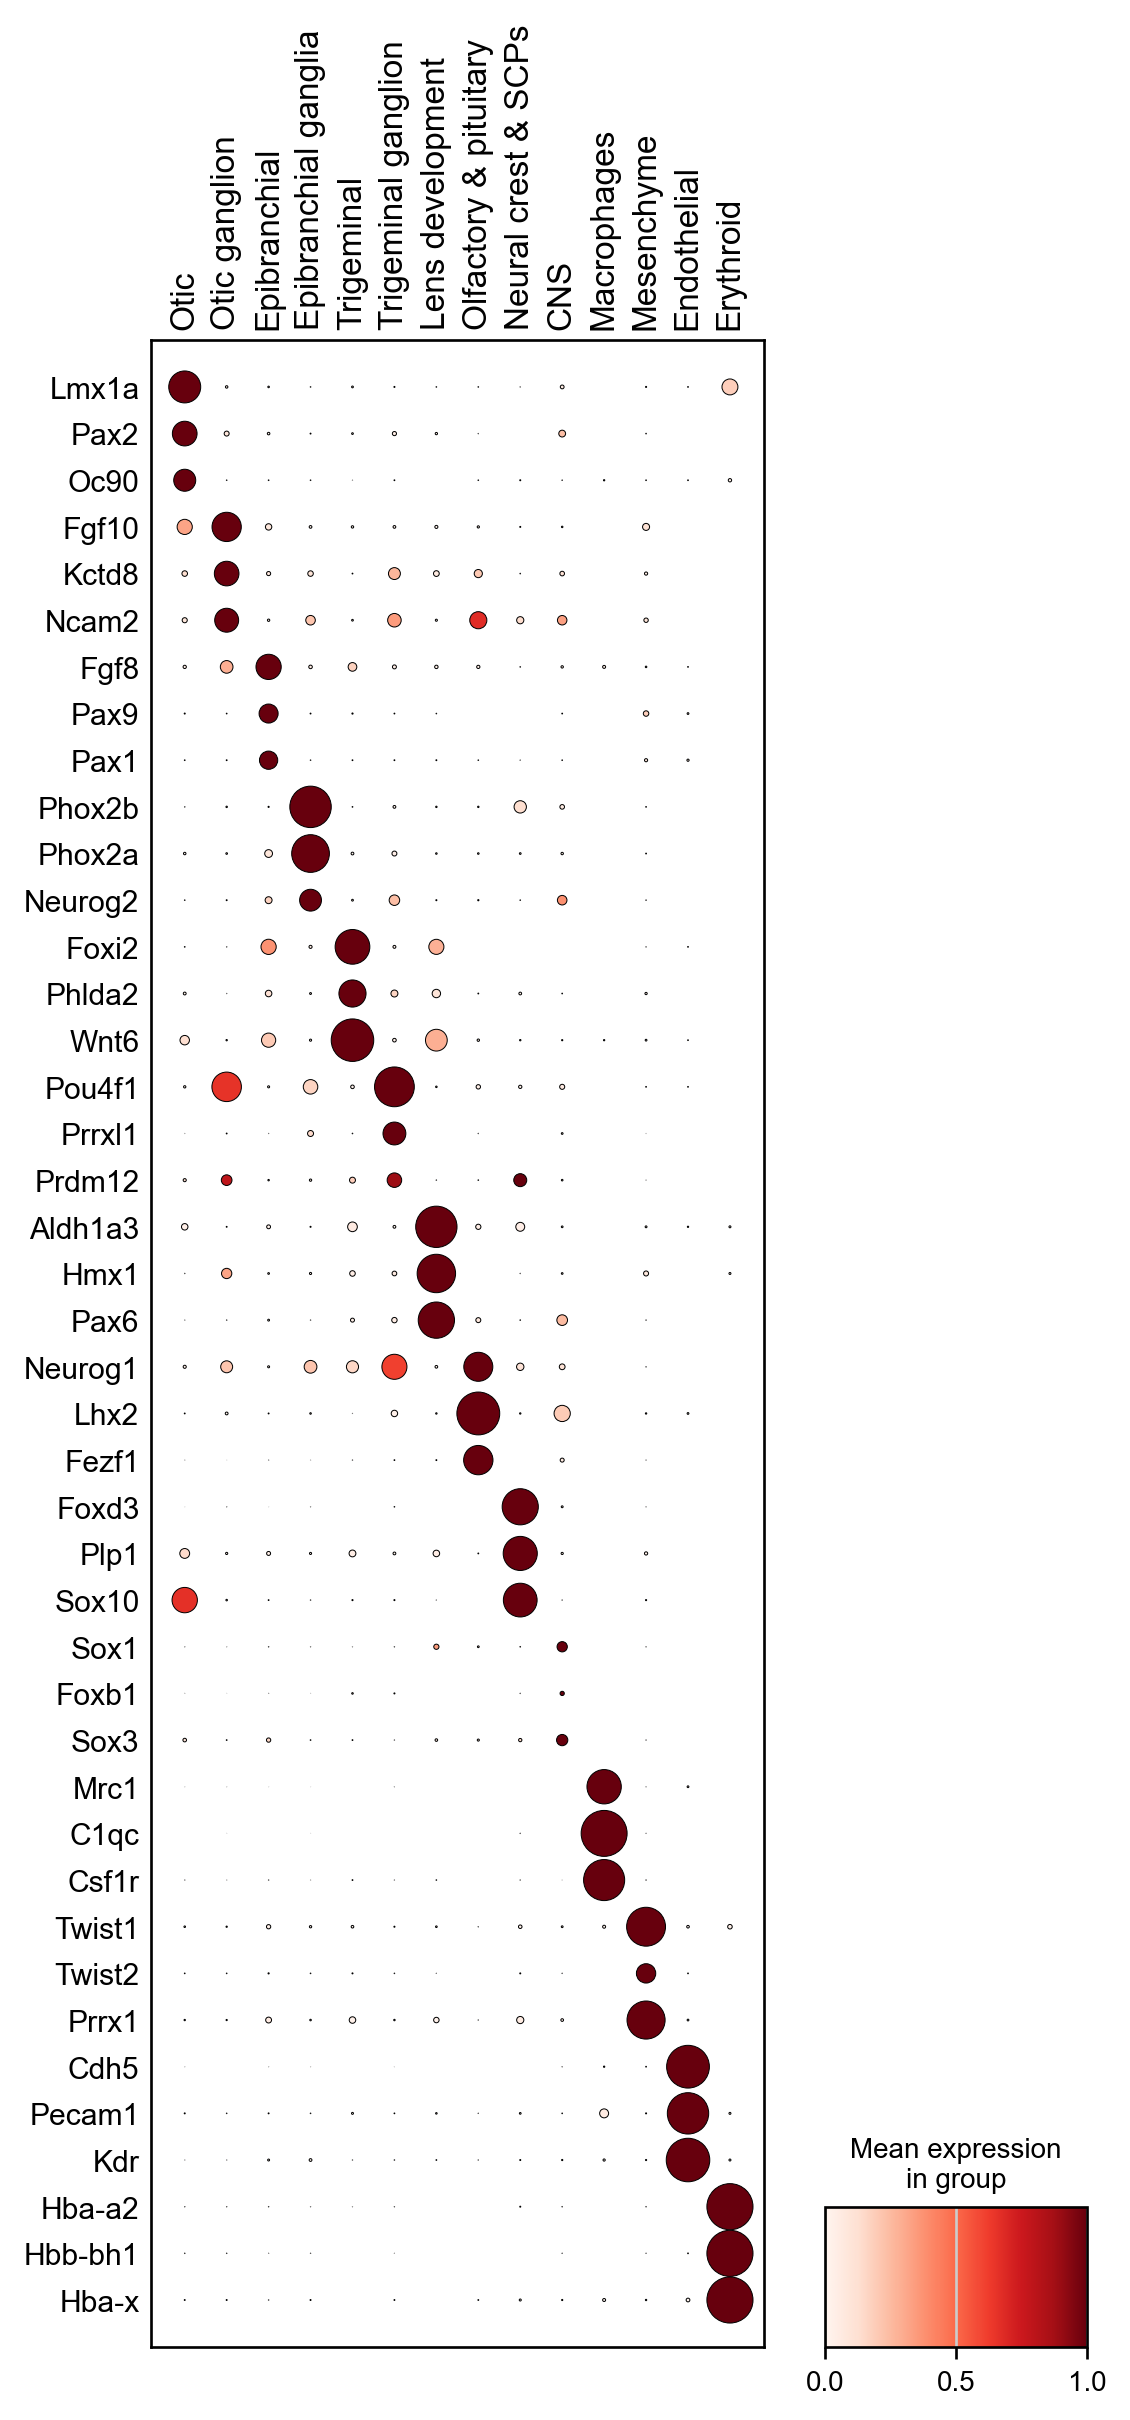

In [9]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd

# ============================================================
# 1. SETTINGS
# ============================================================

KEY = "cell_type"
USE_RAW = False

FIG_WIDTH = 5
FIG_HEIGHT = 11

FONT_SIZE = 10
GENE_FONT = 9
CELL_FONT = 10

DOT_EDGE = 0.3
CMAP = "Reds"

# ============================================================
# 2. MARKER GENES
# ============================================================

specific_genes = {
    "Otic": ["Lmx1a", "Pax2", "Oc90"],

    "Otic ganglion": [
        "Fgf10", "Kctd8", "Ncam2"
    ],

    "Epibranchial": [
        "Fgf8", "Pax9", "Pax1"
    ],

    "Epibranchial ganglia": [
        "Phox2b", "Phox2a", "Neurog2"
    ],

    "Trigeminal": [
        "Foxi2", "Phlda2", "Wnt6"
    ],

    "Trigeminal ganglion": [
      #  "Neurog1",
        "Pou4f1", "Prrxl1", 'Prdm12'
    ],

    "Lens development": [
        "Aldh1a3", "Hmx1", "Pax6"
    ],

    "Olfactory & pituitary": [
       "Neurog1",  "Lhx2", "Fezf1", #"Pou3f2"
    ],

    "Neural crest & SCPs": [
        "Foxd3", "Plp1", "Sox10"
    ],
     "CNS": [ 'Sox1', 'Foxb1',  'Sox3', #'Pax6', 'Hes1', 'Hes5'
       #  'Pou3f2', 
   #"Sox3", 
             #  "Hes5",
   # "Rfx4", 
               #"Zic1", 

    ],

    "Macrophages": [
        "Mrc1", "C1qc", "Csf1r"
    ],

    "Mesenchyme": [
        "Twist1", "Twist2", "Prrx1"
    ],

    "Endothelial": [
        "Cdh5", "Pecam1", "Kdr"
    ],

    "Erythroid": [
        "Hba-a2", "Hbb-bh1", "Hba-x"
    ],

   
}

# ============================================================
# 3. PREPARE DATA
# ============================================================

adata_plot = adata[
    adata.obs[KEY].notna() &
    (adata.obs[KEY].astype(str) != "Unknown")
].copy()

order = [
    ct for ct in specific_genes
    if ct in adata_plot.obs[KEY].astype(str).unique()
]

adata_plot.obs[KEY] = pd.Categorical(
    adata_plot.obs[KEY].astype(str),
    categories=order,
    ordered=True
)

# ============================================================
# 4. CHECK AVAILABLE GENES
# ============================================================

if USE_RAW:
    if adata_plot.raw is None:
        raise ValueError("adata.raw is not available")
    available_genes = set(adata_plot.raw.var_names)
else:
    available_genes = set(adata_plot.var_names)

remove_genes = {
    "Mir124-2hg",
    "C130071C03Rik",
    "2610035D17Rik"
}

specific_genes_filtered = {}

for ct in order:

    genes = specific_genes[ct]

    missing = [
        g for g in genes
        if g not in available_genes
    ]

    if missing:
        print(f"Missing in {ct}: {missing}")

    genes = [
        g for g in genes
        if g in available_genes
        and g not in remove_genes
    ]

    genes = list(dict.fromkeys(genes))

    if genes:
        specific_genes_filtered[ct] = genes

print("\nFINAL MARKER GENES\n")

for ct, genes in specific_genes_filtered.items():
    print(f"{ct}: {len(genes)} — {', '.join(genes)}")

# Flatten gene list and remove duplicates
genes_flat = list(dict.fromkeys(
    g
    for genes in specific_genes_filtered.values()
    for g in genes
))

# ============================================================
# 5. PUBLICATION FIGURE SETTINGS
# ============================================================

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sc.set_figure_params(
    vector_friendly=True,
    dpi=120,
    fontsize=FONT_SIZE
)

# ============================================================
# 6. VERTICAL DOT PLOT
# ============================================================

plot_order = list(specific_genes_filtered.keys())

dp = sc.pl.dotplot(
    adata_plot,
    var_names=genes_flat,       # Flat list removes gene-group brackets
    groupby=KEY,
    categories_order=plot_order,
    use_raw=USE_RAW,
    standard_scale="var",
    swap_axes=True,
    dendrogram=False,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    return_fig=True,
    show=False
)

dp.style(
    cmap=CMAP,
    dot_edge_color="black",
    dot_edge_lw=DOT_EDGE
)

# ============================================================
# 7. REMOVE SIZE LEGEND
# ============================================================

dp.legend(
    show_size_legend=False,
    show_colorbar=True
)

# ============================================================
# 8. MOVE CELL TYPE NAMES TO TOP
# ============================================================

dp.make_figure()

axes = dp.get_axes()
main_ax = axes["mainplot_ax"]

main_ax.xaxis.tick_top()
main_ax.xaxis.set_label_position("top")

main_ax.tick_params(
    axis="x",
    labelsize=CELL_FONT,
    top=True,
    bottom=False,
    labeltop=True,
    labelbottom=False,
    length=0
)

main_ax.tick_params(
    axis="y",
    labelsize=GENE_FONT,
    length=0
)

# Remove axis labels
main_ax.set_xlabel("")
main_ax.set_ylabel("")

# ============================================================
# 9. DISPLAY
# ============================================================
# ============================================================
# 9. SAVE PDF AND SVG
# ============================================================

from pathlib import Path

OUTDIR = Path.cwd()
FILENAME = "Dotplot_cell_type_final"

fig = dp.fig

pdf_path = OUTDIR / f"{FILENAME}.pdf"
svg_path = OUTDIR / f"{FILENAME}.svg"

fig.savefig(
    pdf_path,
    format="pdf",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Saved PDF:", pdf_path)
print("Saved SVG:", svg_path)

plt.show()
plt.show()


FINAL MARKER GENES

Otic: 3 — Lmx1a, Pax2, Oc90
Otic ganglion: 3 — Fgf10, Kctd8, Ncam2
Epibranchial: 3 — Fgf8, Pax9, Pax1
Epibranchial ganglia: 3 — Phox2b, Phox2a, Neurog2
Trigeminal: 3 — Foxi2, Phlda2, Wnt6
Trigeminal ganglion: 3 — Neurog1, Pou4f1, Prrxl1
Lens development: 3 — Aldh1a3, Hmx1, Pax6
Olfactory & pituitary: 3 — Lhx2, Fezf1, Pou3f2
Neural crest & SCPs: 3 — Foxd3, Plp1, Sox10
Macrophages: 3 — Mrc1, C1qc, Csf1r
Mesenchyme: 3 — Twist1, Twist2, Prrx1
Endothelial: 3 — Cdh5, Pecam1, Kdr
Erythroid: 3 — Hba-a2, Hbb-bh1, Hba-x
CNS: 3 — Sox2, Pax6, Rfx4

Total gene positions: 42


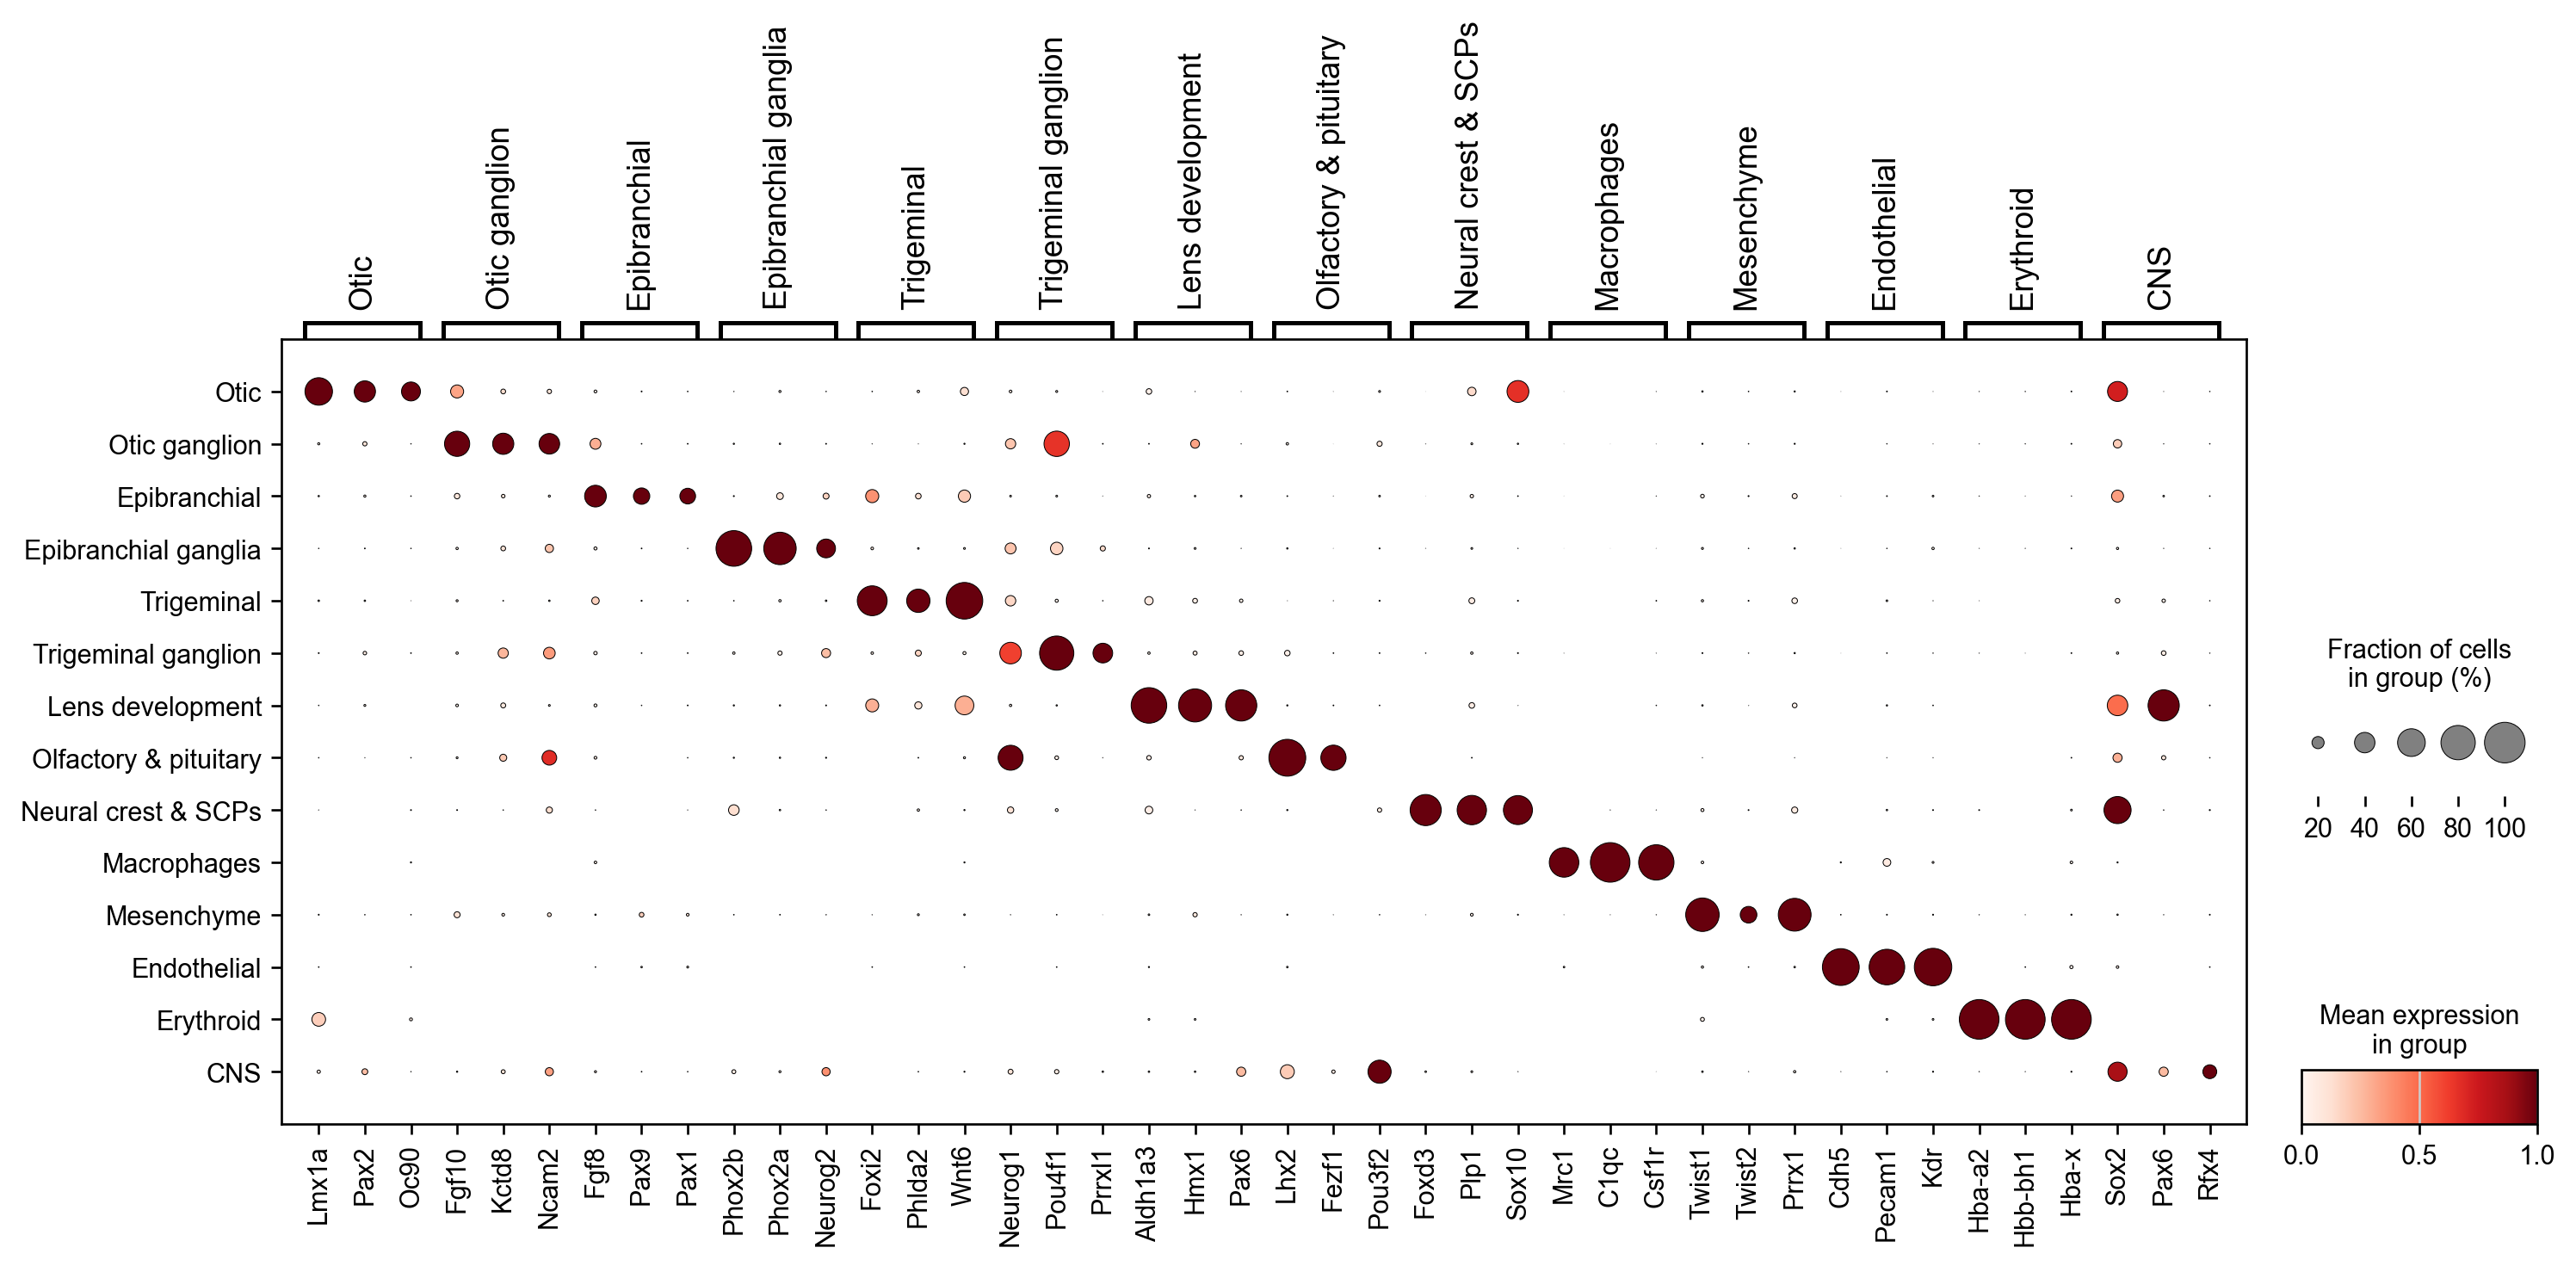

In [10]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd

KEY = "cell_type"
USE_RAW = False
specific_genes = {
"Otic": ["Lmx1a", "Pax2", "Oc90" ],
"Otic ganglion": ['Fgf10', 'Kctd8', 'Ncam2',"Fgf10", ],
"Epibranchial": ['Fgf8','Pax9','Pax1'],
"Epibranchial ganglia": [ "Phox2b", "Phox2a",  "Neurog2", ],
"Trigeminal": [ "Foxi2",  "Phlda2", "Wnt6"  ],
"Trigeminal ganglion": [ "Neurog1",   "Pou4f1","Prrxl1",],
"Lens development": ['Aldh1a3','Hmx1', 'Pax6',],
"Olfactory & pituitary": [  'Lhx2','Fezf1', "Pou3f2"],
"Neural crest & SCPs": [ 'Foxd3', 'Plp1', 'Sox10' ],
"Macrophages": [  "Mrc1",    "C1qc", "Csf1r",],
"Mesenchyme": ["Twist1", "Twist2","Prrx1" ],
"Endothelial": ["Cdh5",  "Pecam1", "Kdr" ], 
"Erythroid": ["Hba-a2", "Hbb-bh1", "Hba-x" ],
   "CNS": ["Sox2", "Pax6", "Rfx4" ], 
}

adata_plot = adata[
    adata.obs[KEY].notna() &
    (adata.obs[KEY].astype(str) != "Unknown")
].copy()

order = [
    ct for ct in specific_genes
    if ct in adata_plot.obs[KEY].astype(str).unique()
]

adata_plot.obs[KEY] = pd.Categorical(
    adata_plot.obs[KEY].astype(str),
    categories=order,
    ordered=True
)


if USE_RAW:
    if adata_plot.raw is None:
        raise ValueError("adata.raw is not available")
    available_genes = set(adata_plot.raw.var_names)
else:
    available_genes = set(adata_plot.var_names)

# Genes we never want to plot
remove_genes = {
    "Mir124-2hg",
    "C130071C03Rik",
    "2610035D17Rik"
}

specific_genes_filtered = {}

for ct in order:

    genes = specific_genes[ct]

    missing = [
        g for g in genes
        if g not in available_genes
    ]

    if missing:
        print(f"Missing in {ct}: {missing}")

    genes = [
        g for g in genes
        if g in available_genes
        and g not in remove_genes
    ]

    # Remove duplicate genes within each group
    genes = list(dict.fromkeys(genes))

    if genes:
        specific_genes_filtered[ct] = genes

print("\nFINAL MARKER GENES\n")

for ct, genes in specific_genes_filtered.items():
    print(f"{ct}: {len(genes)} — {', '.join(genes)}")

n_positions = sum(
    len(genes)
    for genes in specific_genes_filtered.values()
)

print(f"\nTotal gene positions: {n_positions}")

# ============================================================
# 7. PUBLICATION FIGURE SETTINGS
# ============================================================

mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

sc.set_figure_params( vector_friendly=True, dpi=120, fontsize=11)

plot_order = list(specific_genes_filtered)

dp = sc.pl.dotplot(
    adata_plot,
    specific_genes_filtered,
    groupby=KEY,
    categories_order=plot_order,
    use_raw=USE_RAW,
    standard_scale="var",
    dendrogram=False,

    figsize=(
        max(14, n_positions * 0.28),
        max(5, len(plot_order) * 0.35)
    ),

    return_fig=True,
    show=False
)

dp.style(
    cmap="Reds",
    dot_edge_color="black",
    dot_edge_lw=0.3
)

dp.show()